## Kevin Feracho
## DSC 680
## Milestone 3: Final Project

# SkillBridge: Identifying Transferable Career Connections Using Occupational Text

For this project, I wanted to see whether comparing the work people actually do could reveal career connections that job titles might miss. I used occupational descriptions and tasks from O*NET 31.0 to build a text-similarity model and compared it with a simpler job-title model. I also tested an example work-history description to see where the approach worked and where it struggled.

My two main questions were whether tasks and descriptions retrieve more O*NET related occupations than job titles alone, and what limitations appear when I apply the method to an individual work-history example. This is a study of occupational similarity, not proof of a person’s qualifications or transferable skills.

## Import Libraries and Load the O*NET Datasets

I started by importing the libraries needed for data preparation, visualization, and natural language processing. I then loaded six O*NET 31.0 CSV files. Each file contains a different type of occupational information, and the `O*NET-SOC Code` allows me to connect them.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

def load(name):
    candidates = [Path('data')/f'{name}.csv',Path('data')/f'{name}(1).csv',Path(f'{name}.csv'),Path(f'{name}(1).csv'),Path('/mnt/data')/f'{name}(1).csv']
    for p in candidates:
        if p.exists(): return pd.read_csv(p)
    raise FileNotFoundError(f'Missing {name}.csv: place O*NET files in data/')

occ=load('occupation_data'); tasks=load('task_statements'); skills=load('transferable_skills'); acts=load('work_activities'); rel=load('related_occupations'); zones=load('job_zones')
key='O*NET-SOC Code'

The six datasets loaded using the same occupational-code key. I kept the input files separate so I could check their coverage before joining anything.

## Preview the Datasets

Before working with the data, I checked the size, columns, and first few records of each dataset. This helped me understand what each file contains and whether the information loaded correctly.

In [2]:
for name, df in [('Occupations',occ),('Tasks',tasks),('Transferable skills',skills),('Work activities',acts),('Related occupations',rel),('Job zones',zones)]:
    print(f'\n{name}: {df.shape[0]:,} rows x {df.shape[1]} columns')
    print('Columns:', ', '.join(df.columns[:12]))
display(occ.head(3))


Occupations: 1,016 rows x 3 columns
Columns: O*NET-SOC Code, Title, Description

Tasks: 18,838 rows x 8 columns
Columns: O*NET-SOC Code, Title, Task ID, Task, Task Type, Incumbents Responding, Date, Domain Source

Transferable skills: 45,500 rows x 15 columns
Columns: O*NET-SOC Code, Title, Element ID, Element Name, Scale ID, Scale Name, Data Value, N, Standard Error, Lower CI Bound, Upper CI Bound, Recommend Suppress

Work activities: 74,702 rows x 15 columns
Columns: O*NET-SOC Code, Title, Element ID, Element Name, Scale ID, Scale Name, Data Value, N, Standard Error, Lower CI Bound, Upper CI Bound, Recommend Suppress

Related occupations: 18,460 rows x 6 columns
Columns: O*NET-SOC Code, Title, Related O*NET-SOC Code, Related Title, Relatedness Tier, Index

Job zones: 923 rows x 5 columns
Columns: O*NET-SOC Code, Title, Job Zone, Date, Domain Source


,O*NET-SOC Code,Title,Description
0,11-1011.00,Chief Executives,Determine and formulate policies and provide o...
1,11-1011.03,Chief Sustainability Officers,"Communicate and coordinate with management, sh..."
2,11-1021.00,General and Operations Managers,"Plan, direct, or coordinate the operations of ..."


The previews confirmed that these tables contain different types of records. The occupation table has 1,016 occupations, while the task statements cover 923 occupations, which is why I needed to define a consistent modeling population.

## Check Data Quality

I checked for duplicate records, missing occupation codes, and task records that did not match the occupation table. I wanted to identify any problems before joining the files or building the model.

In [3]:
# Data audit: do not drop exact duplicate records blindly; report them.
for name,df in [('Occupations',occ),('Tasks',tasks),('Transferable skills',skills),('Work activities',acts),('Related occupations',rel),('Job zones',zones)]:
    print(f'{name:22} rows={len(df):6,} occupations={df[key].nunique():4,} duplicates={df.duplicated().sum():4,} missing_codes={df[key].isna().sum()}')
print('Task codes absent from occupation master:',len(set(tasks[key])-set(occ[key])))

Occupations            rows= 1,016 occupations=1,016 duplicates=   0 missing_codes=0
Tasks                  rows=18,838 occupations= 923 duplicates=   0 missing_codes=0
Transferable skills    rows=45,500 occupations= 910 duplicates=   0 missing_codes=0
Work activities        rows=74,702 occupations= 911 duplicates=   0 missing_codes=0
Related occupations    rows=18,460 occupations= 923 duplicates=   0 missing_codes=0
Job zones              rows=   923 occupations= 923 duplicates=   0 missing_codes=0
Task codes absent from occupation master: 0


The checks did not find exact duplicate rows, missing occupation codes, or unmatched task occupation codes. That gave me more confidence in the key used for joining the data.

## Review Missing Values

I also looked at missing values in each dataset. Some missing fields may reflect how O*NET records occupational information, so I did not assume that every blank value was an error.

In [4]:
audit=[]
for name,df in [('Occupations',occ),('Tasks',tasks),('Transferable skills',skills),('Work activities',acts),('Related occupations',rel),('Job zones',zones)]:
    audit.append({'dataset':name,'rows':len(df),'occupations':df[key].nunique(),'exact_duplicates':int(df.duplicated().sum()),'missing_codes':int(df[key].isna().sum()),'missing_cells':int(df.isna().sum().sum())})
audit_df=pd.DataFrame(audit)
display(audit_df)
audit_df.to_csv('data_quality.csv',index=False)

,dataset,rows,occupations,exact_duplicates,missing_codes,missing_cells
0,Occupations,1016,1016,0,0,0
1,Tasks,18838,923,0,0,1005
2,Transferable skills,45500,910,0,0,22750
3,Work activities,74702,911,0,0,121777
4,Related occupations,18460,923,0,0,0
5,Job zones,923,923,0,0,0


The datasets do not all cover the same number of occupations. That matters because a missing skill record does not mean someone lacks a skill. I kept the original data unchanged and saved the audit results separately.

## Prepare and Combine the Occupational Text

Next, I combined unique task statements with their matching occupation descriptions using the O*NET-SOC Code. I filled missing description text with empty strings and kept occupations with task statements so that the model would compare similar types of records.

In [5]:
# Join occupation descriptions to unique task statements using the O*NET-SOC code.
task_text=(tasks.dropna(subset=['Task']).drop_duplicates([key,'Task']).groupby(key)['Task'].apply(lambda s:' '.join(s.astype(str))).rename('task_text'))
base=occ[[key,'Title','Description']].drop_duplicates(key).join(task_text,on=key)
base['task_text']=base['task_text'].fillna('');base['Description']=base['Description'].fillna('')
base['text']=(base['Description']+' '+base['task_text']).str.strip()
model=base[base['task_text'].str.len()>0].reset_index(drop=True)
print('Modeled occupations:',len(model))

Modeled occupations: 923


I used the occupational code to join descriptions and distinct task statements. Combining the text gave the model more information than a title alone could provide.

## Check the Combined Dataset

After joining the information, I checked that each occupation appeared only once. Each row should represent one occupation with its combined description and tasks.

In [6]:
print('Unique modeled occupations:',model[key].nunique())
print('Duplicate occupation IDs after join:',model[key].duplicated().sum())
display(model[[key,'Title','Description','task_text']].head(3))

Unique modeled occupations: 923
Duplicate occupation IDs after join: 0


,O*NET-SOC Code,Title,Description,task_text
0,11-1011.00,Chief Executives,Determine and formulate policies and provide o...,Direct or coordinate an organization's financi...
1,11-1011.03,Chief Sustainability Officers,"Communicate and coordinate with management, sh...",Monitor and evaluate effectiveness of sustaina...
2,11-1021.00,General and Operations Managers,"Plan, direct, or coordinate the operations of ...","Review financial statements, sales or activity..."


The combined data contains 923 unique occupations without duplicate occupation IDs after the join. This is the group I used for both model comparisons.

## Explore Occupational Coverage

I created a chart to compare how many occupations were represented in the six source tables. This gave me a clearer picture of the available data before modeling.

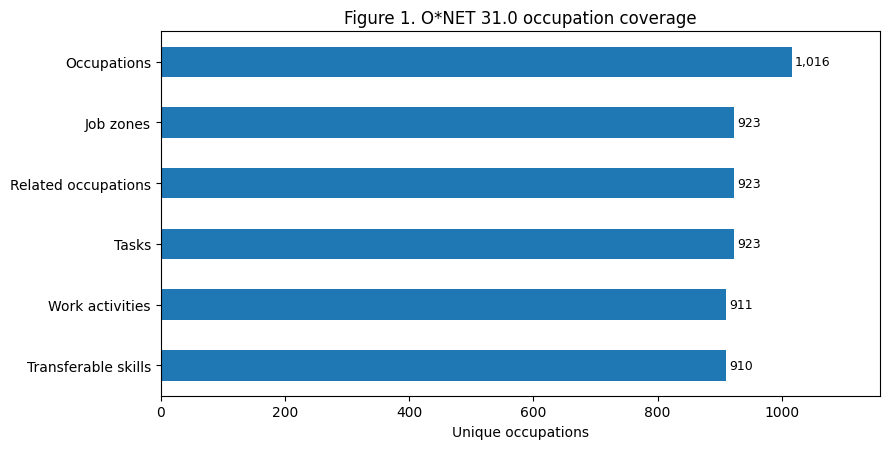

In [7]:
coverage=pd.Series({'Occupations':occ[key].nunique(),'Tasks':tasks[key].nunique(),'Transferable skills':skills[key].nunique(),'Work activities':acts[key].nunique(),'Related occupations':rel[key].nunique(),'Job zones':zones[key].nunique()})
fig,ax=plt.subplots(figsize=(9,4.6))
coverage.sort_values().plot.barh(ax=ax)
ax.set(title='Figure 1. O*NET 31.0 occupation coverage',xlabel='Unique occupations')
for p in ax.patches: ax.text(p.get_width()+5,p.get_y()+p.get_height()/2,f'{int(p.get_width()):,}',va='center',fontsize=9)
ax.set_xlim(0,max(coverage)*1.14);fig.tight_layout();fig.savefig('figure_1_coverage.png',dpi=160);plt.show()

The chart shows that the main occupation file covers more occupations than some of the detailed tables. Since my model uses task statements, I limited the analysis to the 923 occupations with task data. The findings should not automatically be applied to every occupation in O*NET.

## Build the TF-IDF Similarity Models

I used TF-IDF to convert the occupational text into numerical features and cosine similarity to compare occupations. I built two models: one using tasks and descriptions, and another using only job titles. Comparing them helped me see whether the extra information made a difference.

In [8]:
# Baseline TF-IDF models: occupation text versus job title only.
vectorizer=TfidfVectorizer(stop_words='english',ngram_range=(1,2),min_df=2,max_features=30000,sublinear_tf=True)
X=vectorizer.fit_transform(model['text'])
title_vectorizer=TfidfVectorizer(stop_words='english',ngram_range=(1,2))
Xt=title_vectorizer.fit_transform(model['Title'])
S=linear_kernel(X,X); St=linear_kernel(Xt,Xt)
np.fill_diagonal(S,-1);np.fill_diagonal(St,-1)

Both models use the same 923 occupations. That makes the comparison more meaningful because the main difference is the amount of text each model uses.

I excluded each occupation from its own recommendations. Otherwise, the model would give itself a perfect match and make the evaluation less meaningful. These similarity scores measure text overlap, not someone’s likelihood of getting hired.

## Evaluate the Models

To compare the models, I used O*NET related-occupation links as a reference. I measured Precision@10, Recall@10, and whether the top ten recommendations contained at least one related occupation. These are useful comparison measures, but they are not proof that a person could successfully change careers.

In [9]:
# External *proxy* relevance labels: O*NET related-occupation links.
code_to_idx={code:i for i,code in enumerate(model[key])}
related=rel[rel[key].isin(code_to_idx)&rel['Related O*NET-SOC Code'].isin(code_to_idx)].groupby(key)['Related O*NET-SOC Code'].apply(set).to_dict()
rows=[]
for i,code in enumerate(model[key]):
    truth=related.get(code,set())
    if not truth: continue
    for label,similarities in [('Tasks + descriptions',S),('Job title only',St)]:
        top=np.argsort(-similarities[i])[:10]
        hits=sum(model.iloc[j][key] in truth for j in top)
        rows.append({'occupation':code,'model':label,'precision_at_10':hits/10,'recall_at_10':hits/len(truth),'any_hit_at_10':int(hits>0)})
metrics=pd.DataFrame(rows)
summary=metrics.groupby('model')[['precision_at_10','recall_at_10','any_hit_at_10']].mean()
print('Evaluated occupations:',metrics.occupation.nunique())
display(summary)

Evaluated occupations: 923


,precision_at_10,recall_at_10,any_hit_at_10
model,,,
Job title only,0.305200,0.152600,0.851571
Tasks + descriptions,0.679307,0.339653,0.998917


The evaluation compares each occupation’s ten closest matches with O*NET’s documented related occupations. The results describe agreement with that reference, not actual career outcomes.

## Compare the Model Results

I plotted the evaluation results to see how the task-based model compared with the title-only model across the three metrics.

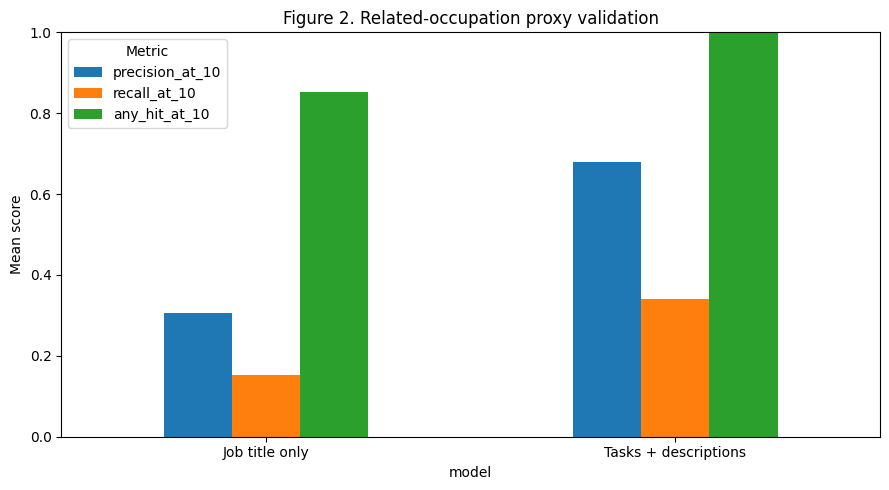

In [10]:
fig,ax=plt.subplots(figsize=(9,5))
summary.plot.bar(ax=ax,rot=0)
ax.set(title='Figure 2. Related-occupation proxy validation',ylabel='Mean score',ylim=(0,1))
ax.legend(title='Metric');fig.tight_layout();fig.savefig('figure_2_validation.png',dpi=160);plt.show()
summary.to_csv('evaluation_metrics.csv')

The task-and-description model performed better on the O*NET related-occupation benchmark. Precision@10 was about 67.93%, compared with 30.52% for titles alone. Recall@10 also improved from 15.26% to 33.97%. This means the richer text retrieved more occupations that O*NET already identifies as related. It does not mean the model can identify personal skills with 67.93% accuracy.

## Test a Work-History Example

I wanted to see what the model would do with a more realistic example, so I used a description of analyzing alarm events, investigating false alarms, preparing Power BI reports, and explaining findings to customers. This is an illustration, not a separate validation test. The skill labels displayed with the results describe O*NET occupations, not skills verified about the person.

In [11]:
# Example query: illustrative only, not a held-out test case.
query='I analyzed customer alarm event histories, investigated recurring false alarms, created Power BI reports, and explained patterns to customers.'
scores=linear_kernel(vectorizer.transform([query]),X).ravel()
ranked=np.argsort(-scores)[:10]
imp=skills[(skills['Scale ID']=='IM')&(skills['Recommend Suppress'].fillna('N')!='Y')].copy()
imp['Data Value']=pd.to_numeric(imp['Data Value'],errors='coerce')
skillmap=imp.sort_values('Data Value',ascending=False).groupby(key).apply(lambda g:list(dict.fromkeys(g['Element Name'].dropna().tolist()))[:5],include_groups=False).to_dict()
results=pd.DataFrame([{'occupation':model.iloc[i]['Title'],'similarity':scores[i],'associated_onet_skills':'; '.join(skillmap.get(model.iloc[i][key],[]))} for i in ranked])
display(results)

,occupation,similarity,associated_onet_skills
0,Security and Fire Alarm Systems Installers,0.144067,Installation; Quality Control Analysis; Judgme...
1,Fire Inspectors and Investigators,0.124703,Social Perceptiveness; Persuasion; Instructing...
2,"Meeting, Convention, and Event Planners",0.076770,Social Perceptiveness; Coordination; Service O...
3,First-Line Supervisors of Firefighting and Pre...,0.074000,Management of Personnel Resources; Judgment an...
4,Fashion Designers,0.058303,Judgment and Decision Making; Time Management;...
5,Craft Artists,0.054826,Judgment and Decision Making; Social Perceptiv...
6,"Disc Jockeys, Except Radio",0.050353,Social Perceptiveness; Time Management; Servic...
7,Public Safety Telecommunicators,0.049516,Social Perceptiveness; Coordination; Service O...
8,"Patternmakers, Metal and Plastic",0.048585,Operation and Control; Operations Monitoring; ...
9,"Janitors and Cleaners, Except Maids and Housek...",0.045628,Time Management; Coordination; Social Percepti...


The example produced a mixture of relevant and questionable occupations. It was useful for spotting limitations, but it was not a labeled test of skill extraction.

## Visualize the Example Recommendations

This chart shows the occupations with the highest cosine similarity scores for the example. A longer bar means more similarity in the text, not necessarily a better career fit.

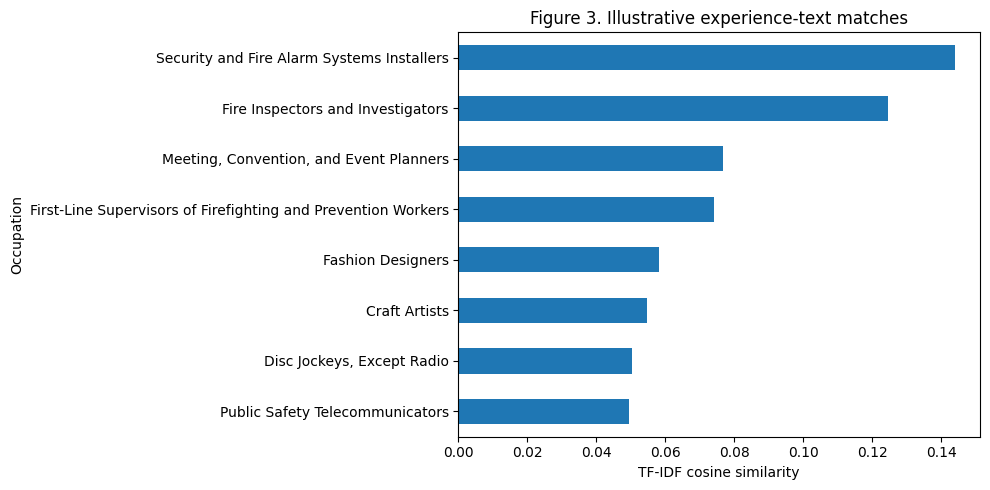

In [12]:
fig,ax=plt.subplots(figsize=(10,5))
results.head(8).iloc[::-1].plot.barh(x='occupation',y='similarity',legend=False,ax=ax)
ax.set(title='Figure 3. Illustrative experience-text matches',xlabel='TF-IDF cosine similarity',ylabel='Occupation')
fig.tight_layout();fig.savefig('figure_3_example.png',dpi=160);plt.show()
results.to_csv('example_matches.csv',index=False)

Some matches were related to security work, but others were unexpected, including fashion designers and disc jockeys. This helped me see how matching words can produce recommendations that do not make much sense for a real career transition. The example also showed why I should not treat similarity scores as proof of transferable skills.

## Review the SkillBridge Workflow

I created a simple diagram showing how the data moves through the prototype, from the occupational text to TF-IDF features, similarity rankings, and O*NET skill context. The skill information is displayed after matching rather than being used as verified personal skill extraction.

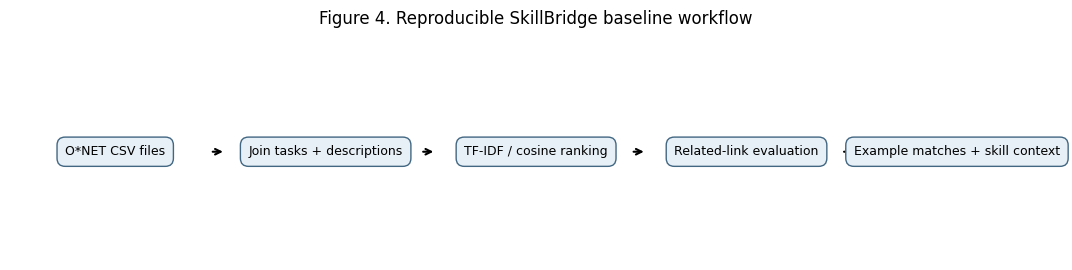

In [13]:
fig,ax=plt.subplots(figsize=(11,2.8));ax.axis('off')
steps=['O*NET CSV files','Join tasks + descriptions','TF-IDF / cosine ranking','Related-link evaluation','Example matches + skill context']
for i,s in enumerate(steps):
    x=0.015+i*.2
    ax.text(x+.085,.52,s,ha='center',va='center',fontsize=9,wrap=True,transform=ax.transAxes,bbox={'boxstyle':'round,pad=.65','fc':'#e8f0f7','ec':'#426782'})
    if i<4:ax.annotate('',xy=(x+.19,.52),xytext=(x+.175,.52),xycoords='axes fraction',textcoords='axes fraction',arrowprops={'arrowstyle':'->','lw':1.5})
ax.set_title('Figure 4. Reproducible SkillBridge baseline workflow',pad=20);fig.tight_layout();fig.savefig('figure_4_workflow.png',dpi=160);plt.show()

This workflow summarizes the prototype I actually built. It does not include personalized skill verification or automated career eligibility decisions.

## Limitations and Ethical Considerations

There are several limitations to this project. TF-IDF relies on word patterns, so it may miss similar responsibilities described with different wording. It also does not verify experience, proficiency, education, or licensing requirements. The O*NET related-occupation links are useful reference labels, but they do not measure actual career transitions.

Fairness is another concern. People with unusual work histories or different ways of describing their experience might receive less relevant results. If SkillBridge were developed further, I would test it with different career backgrounds and include human feedback.

Privacy would also matter if people uploaded real resumes. This version used public O*NET data and an illustrative description, but a future system would need consent and safeguards for personal information. Most importantly, I would present the results as career exploration suggestions rather than hiring or eligibility decisions.

The source files came from O*NET 31.0, and I preserved the original data and documented the joins and coverage restrictions.

## Conclusion and Future Improvements

The results showed that comparing tasks and descriptions was more effective than comparing job titles alone on the O*NET related-occupation benchmark. However, the work-history example also showed that identifying similar words is not the same as understanding a person’s skills.

If I continued this project, I would test semantic embeddings, have people review the relevance of recommendations, and include education, job-zone, and licensing information. I would also need a separate evaluation for identifying specific skills from work histories before treating SkillBridge as a real career guidance tool.

## References

National Center for O*NET Development. (2026). *O*NET 31.0 database*. O*NET Resource Center. https://www.onetcenter.org/database.html

National Center for O*NET Development. (n.d.). *O*NET database license*. O*NET Resource Center. https://www.onetcenter.org/license_db.html

Schlippe, T., & Bothmer, K. (2023). Skill Scanner: An AI-based recommendation system for employers, job seekers and educational institutions. *International Journal of Advanced Corporate Learning, 16*(1), 55–64. https://doi.org/10.3991/ijac.v16i1.34779

## Reproducing the Analysis

Keep this notebook next to the `data` folder containing the six O*NET CSV files. In JupyterLab, select **Run → Run All Cells**. The notebook creates the data-quality summary, evaluation metrics, example recommendations, and four figures. The required Python libraries are pandas, numpy, matplotlib, and scikit-learn.